In [1]:
# Problem 1: Automatically generate text

# A Walmart employee needs to inform a customer that order WMT-104 is ready at pickup bay 3.

# Instead of writing everything manually, a Hugging Face text-generation model drafts pickup updates, product descriptions, and shift-handover messages.

# Model: google/flan-t5-small

In [2]:
# Problem 2: Prepare business documents for intelligent search

# Walmart has procedures for pickups, returns, and inventory. Employees may not know which procedure contains the information they need.

# The notebook converts procedure descriptions and a search query into numerical vectors called embeddings.

# These vectors can later be compared to identify related procedures.

# Model: sentence-transformers/paraphrase-MiniLM-L3-v2

In [3]:
# Problem 3: Understand images automatically

# Suppose Walmart has a photograph of a product shelf.

# An AI model can examine the photograph and generate a short description of what it sees.

# Model: Salesforce/blip-image-captioning-base

In [4]:
# Problem 4: Generate promotional images

# Walmart wants to visualize a promotional campaign for grocery pickup.

# Instead of manually preparing an initial concept, the employee provides a text description and AI generates an illustrative image.

# Model: stabilityai/sd-turbo, through Hugging Face Diffusers.

In [5]:
# Problem 5: Understand customer feedback

# A customer writes, "My grocery pickup order was ready when I arrived."

# The AI determines whether the feedback expresses positive or negative sentiment.

# Model: distilbert/distilbert-base-uncased-finetuned-sst-2-english

## Run text generation and embedding pipelines

In [6]:
%pip install -q "transformers>=4.46,<5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [1]:
# Requires Transformers 4.x; no HF_TOKEN is needed for these public models.
from transformers import pipeline
import gc

# Generate short Walmart training drafts.
print("Loading the text model; first use downloads it once.")
text_generator = pipeline(
    "text2text-generation",
    model="google/flan-t5-small",
    device=-1,
)

generation_examples = [
    (
        "Pickup update",
        "Write a brief pickup update using only these facts: "
        "Walmart training order WMT-104 is ready at bay 3.",
    ),
    (
        "Product description",
        "Write a short product description using only these facts: "
        "reusable grocery bags, durable, 2-pack.",
    ),
    (
        "Shift handoff",
        "Write a short shift handoff using only these facts: "
        "pickup orders are ready; bay 3 is open.",
    ),
]

for label, prompt in generation_examples:
    result = text_generator(
        prompt,
        max_new_tokens=40,
        do_sample=False,
        truncation=True,
    )
    print(label + ":", result[0]["generated_text"].strip())

# Free the text model before loading the embedding model.
del text_generator, result
gc.collect()

# Create an embedding for a search query.
print("Loading the embedding model; first use downloads it once.")
embedding_pipeline = pipeline(
    "feature-extraction",
    model="sentence-transformers/paraphrase-MiniLM-L3-v2",
    device=-1,
)

pipeline_prompt = "Find the curbside pickup procedure for a training order."
token_features = embedding_pipeline(
    pipeline_prompt,
    return_tensors=True,
    truncation=True,
    max_length=128,
)
pickup_embedding = token_features.mean(dim=1)[0]
print("Search-query embedding shape:", tuple(pickup_embedding.shape))

# Define a small local Walmart procedure corpus and embed each procedure.
walmart_procedures = {
    "PICKUP": "Customers check in through the app and park in a marked pickup bay.",
    "RETURNS": "For a damaged pickup item, direct the customer to the service desk.",
    "INVENTORY": "Check the product SKU and confirm shelf availability.",
}

procedure_embeddings = {}
for procedure_id, text in walmart_procedures.items():
    token_features = embedding_pipeline(
        text,
        return_tensors=True,
        truncation=True,
        max_length=128,
    )
    procedure_embeddings[procedure_id] = token_features.mean(dim=1)[0]

print("Procedure embeddings stored:", list(procedure_embeddings))

Loading the text model; first use downloads it once.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

... (8 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cpu


Search-query embedding shape: (384,)
Procedure embeddings stored: ['PICKUP', 'RETURNS', 'INVENTORY']


#### Multimodal image understanding

A vision-language model takes an image and returns text. This can help an associate draft a description of a shelf display, but it is not an authoritative product/SKU identifier or inventory count. Use only approved, non-customer training photos. Image inference runs locally after the public model downloads; the image is not sent to Hugging Face.

In [2]:
# Optional: set this to True only after adding an approved training photo.
RUN_IMAGE_CAPTIONING = True
from pathlib import Path
# image_path = Path("walmart_shelf_training.jpg")
image_path = Path("/content/walmart_shelf_training.jpg")
if RUN_IMAGE_CAPTIONING and image_path.exists():
    image_captioner = pipeline("image-to-text", model="Salesforce/blip-image-captioning-base", device=-1)
    caption = image_captioner(str(image_path), max_new_tokens=40)
    print("Draft image description:", caption[0]["generated_text"])
elif RUN_IMAGE_CAPTIONING:
    print("Add an approved photo as walmart_shelf_training.jpg before running this demo.")
else:
    print("Optional image captioning is off. Set RUN_IMAGE_CAPTIONING=True to try it.")

config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/auto/modeling_auto.py:2284: FutureWarning: The class `AutoModelForVision2Seq` is deprecated and will be removed in v5.0. Please use `AutoModelForImageTextToText` instead.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Device set to use cpu


Draft image description: a store shelf with school supplies and supplies for sale in the store


#### Image generation

A text-to-image model can create a rough seasonal pickup-campaign concept for discussion, not a final Walmart asset. This public model does not require `HF_TOKEN`, but its files are about 1 GB and image generation is resource-intensive. Do not enable this during the timed lab or on a slow connection. Install Diffusers with `%pip install -q diffusers` only if you intend to run it; the code cell is off by default.

In [3]:
%pip install -q -U diffusers transformers accelerate safetensors


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Running on: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/1 [00:00<?, ?it/s]

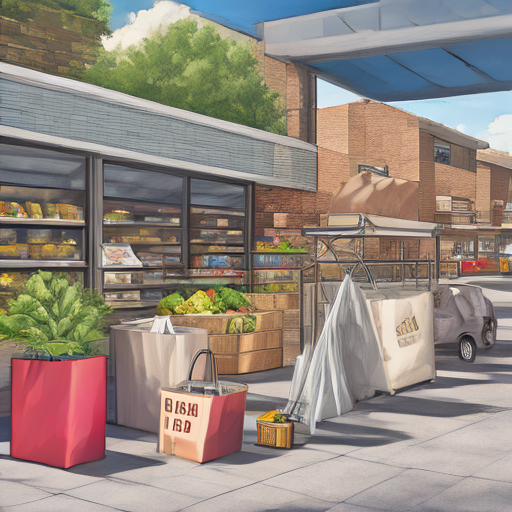

Image generated successfully!


In [1]:
# 3 minutes
import torch
from diffusers import AutoPipelineForText2Image
from IPython.display import display

# Check GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

# Load lightweight, fast image generation model
pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    variant="fp16" if device == "cuda" else None
)

pipe = pipe.to(device)

# Business use case
prompt = (
    "Professional illustration of grocery shopping bags "
    "beside a curbside pickup bay, bright daylight, "
    "modern retail environment, no logos, no text"
)

# Generate image
with torch.inference_mode():
    image = pipe(
        prompt=prompt,
        num_inference_steps=1,
        guidance_scale=0.0,
        height=512,
        width=512
    ).images[0]

# Display and save
display(image)
image.save("pickup_campaign_concept.png")

print("Image generated successfully!")


#### Additional use case: feedback sentiment

A text-classification pipeline can sort fictional, redacted training feedback into broad positive/negative labels. This general model is only a demonstration, not a measure of customer satisfaction or a substitute for Walmart-approved analysis.

In [2]:
# Optional: set True only when you want to download and try the public sentiment model.
from transformers import pipeline
RUN_SENTIMENT_DEMO = True
if RUN_SENTIMENT_DEMO:
    feedback_classifier = pipeline(
        "text-classification",
        model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
        device=-1,
    )
    sample_feedback = "My grocery pickup order was ready when I arrived."
    print(feedback_classifier(sample_feedback)[0])
else:
    print("Optional feedback classification is off. Set RUN_SENTIMENT_DEMO=True to try it.")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

{'label': 'NEGATIVE', 'score': 0.9912112355232239}


In [3]:
# Optional: set True only when you want to download and try the public sentiment model.
from transformers import pipeline
RUN_SENTIMENT_DEMO = True
if RUN_SENTIMENT_DEMO:
    feedback_classifier = pipeline(
        "text-classification",
        model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
        device=-1,
    )
    sample_feedback = "I am happy with the food at this restaurant."
    print(feedback_classifier(sample_feedback)[0])
else:
    print("Optional feedback classification is off. Set RUN_SENTIMENT_DEMO=True to try it.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'label': 'POSITIVE', 'score': 0.9998843669891357}


# Happy Learning